# Notebook 02: Exact-mass features

Notebook 01 bins the spectra to whole-number m/z. This notebook builds extra features from the exact masses in `peaks.csv`.

Created Features:
- Group A: mass defect and nitrogen rule (6 columns).
- Group B: formula from the precursor mass (10).
- Group C: neutral losses (1,950). Group D: spectrum summaries (12).

## Load the data

### Libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

In [2]:
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"])
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

### Peaks
Cleaned peaks with their exact m/z, one row per peak (saved by notebook 01).

In [3]:
peaks = pd.read_csv("../data/processed/peaks.csv", float_precision="round_trip")
peaks.head()

,inchikey,energy,mz,intensity
0,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,LOW,167.0881,0.086163
1,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,LOW,183.0828,0.066435
2,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,LOW,195.1187,0.352127
3,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,LOW,196.1220,0.143065
4,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,LOW,224.1449,0.140089


### Compounds

In [4]:
compounds = pd.read_csv("../data/processed/compounds.csv", skipinitialspace=True)
compounds.columns = compounds.columns.str.strip()
text = ["inchikey", "name", "formula", "smiles"]
compounds[text] = compounds[text].apply(lambda col: col.str.strip())
compounds = compounds.set_index("inchikey")

### Spectra of notebook 01
Only the 1,951 columns of notebook 01 are kept, so a rerun starts from the same matrix.

In [5]:
X = pd.read_csv("../data/processed/X.csv", index_col="inchikey", float_precision="round_trip")
X = X.filter(regex="^(LOW|MID|HIGH)_|^precursor_mz$")
assert X.shape[1] == 1951
compounds = compounds.loc[X.index]
precursor = compounds.precursor_mz

### Precursor m/z on every peak

In [6]:
peaks = peaks.join(precursor, on="inchikey")
peaks.head()

,inchikey,energy,mz,intensity,precursor_mz
0,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,LOW,167.0881,0.086163,226.1596
1,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,LOW,183.0828,0.066435,226.1596
2,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,LOW,195.1187,0.352127,226.1596
3,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,LOW,196.1220,0.143065,226.1596
4,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,LOW,224.1449,0.140089,226.1596


### Binning
One column per unit of m/z and level, keeping the strongest peak (as in notebook 01).

In [7]:
LEVELS = ["LOW", "MID", "HIGH"]


def bin_spectra(peaks, value, name):
    table = peaks.assign(bin=peaks[value].astype(int)).query("bin < 650")
    wide = table.pivot_table(index="inchikey", columns=["energy", "bin"], values="intensity", aggfunc="max")
    wide = wide.reindex(columns=pd.MultiIndex.from_product([LEVELS, range(650)])).fillna(0)
    wide.columns = [name.format(level=level, bin=bin) for level, bin in wide.columns]
    return wide.loc[X.index]

### Check
Binning `peaks.csv` again must give the bins of `X.csv`.

In [8]:
rebuilt = bin_spectra(peaks, "mz", "{level}_{bin}")
(rebuilt - X.iloc[:, :1950]).abs().max().max()

0.0

## Group A: mass defect and nitrogen rule

- Mass defect: m/z minus the nearest whole number. Hydrogen raises it; oxygen, sulfur and halogens lower it.
- Nitrogen rule: an odd precursor m/z means an even number of nitrogens.
- Kendrick defect: mass defect after rescaling CH2 to exactly 14, so compounds that differ by CH2 groups share it.

### Precursor features

In [9]:
kendrick = precursor * 14 / 14.01565
A = pd.DataFrame({
    "A_odd_mass": precursor.round() % 2,
    "A_mass_defect": precursor - precursor.round(),
    "A_kendrick_defect": kendrick.round() - kendrick,
})

### Fragment mass defect
Average over the peaks of each level, weighted by intensity.

In [10]:
spectrum = ["inchikey", "energy"]
by_spectrum = peaks.assign(defect=(peaks.mz - peaks.mz.round()) * peaks.intensity).groupby(spectrum)
fragment_defect = by_spectrum.defect.sum() / by_spectrum.intensity.sum()

In [11]:
A = A.join(fragment_defect.unstack("energy")[LEVELS].add_prefix("A_peak_defect_"))
A.describe().T[["mean", "min", "max"]]

,mean,min,max
A_odd_mass,0.517197,0.000000,1.000000
A_mass_defect,0.167015,-0.107900,0.400500
A_kendrick_defect,0.165354,-0.497251,0.493188
A_peak_defect_LOW,0.125190,-0.048114,0.346288
A_peak_defect_MID,0.102818,-0.058330,0.273000
A_peak_defect_HIGH,0.082038,-0.045753,0.212748


### Nitrogen rule check
Share of compounds whose parity agrees with the number of nitrogens in the formula.

In [12]:
n_atoms = compounds.formula.str.extract(r"N(\d+)")[0].astype(float).fillna(0)
((n_atoms % 2 == 0) == (A.A_odd_mass == 1)).mean()

0.9949044585987261

### Mass defect against m/z
By parity of the precursor mass (nitrogen rule).

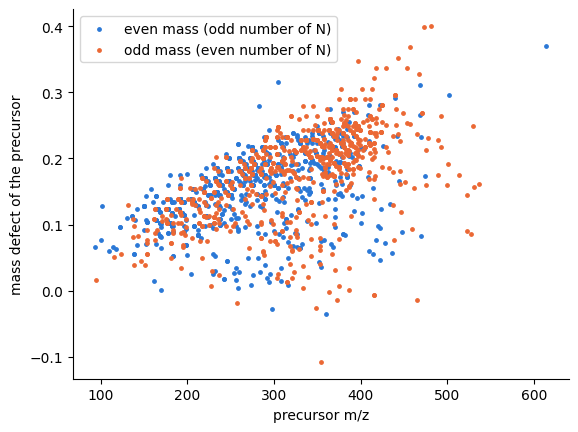

In [13]:
for odd, label in [(0, "even mass (odd number of N)"), (1, "odd mass (even number of N)")]:
    plt.scatter(precursor[A.A_odd_mass == odd], A.A_mass_defect[A.A_odd_mass == odd], s=6, label=label)
plt.legend()
plt.xlabel("precursor m/z")
plt.ylabel("mass defect of the precursor")
plt.savefig("../reports/figures/02_mass_defect.png", dpi=150, bbox_inches="tight")
plt.show()

### Fragment mass defect by level

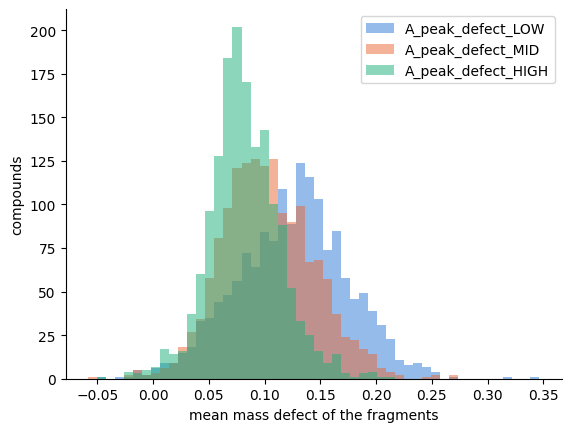

In [14]:
A.filter(like="A_peak_defect").plot.hist(bins=50, alpha=0.5)
plt.xlabel("mean mass defect of the fragments")
plt.ylabel("compounds")
plt.savefig("../reports/figures/02_peak_defect.png", dpi=150, bbox_inches="tight")
plt.show()

## Group B: formula from the precursor mass

- Only a few formulas (C, H, N, O, S, F, Cl, Br) match the precursor mass to a few ppm, and chemical rules remove more.
- Several can still fit, so each candidate gets a weight (small mass error, no rare element) and the features are weighted averages.
- The library's precursor m/z is the molecule plus a hydrogen atom (1.007825), checked below.

### Constants

In [15]:
MASS = pd.Series({"C": 12.0, "H": 1.00782503, "N": 14.0030740, "O": 15.9949146,
                  "S": 31.9720707, "F": 18.9984032, "Cl": 34.9688527, "Br": 78.9183376})
RANGES = {"C": (1, 50), "N": (0, 10), "O": (0, 12), "S": (0, 2), "F": (0, 6), "Cl": (0, 3), "Br": (0, 2)}
ELEMENTS = list(RANGES)
TOLERANCE_PPM, TOLERANCE_DA = 5, 5e-4
SIGMA_PPM, RARE_WEIGHT = 0.3, 0.3

### True formulas
Used only for checks. Compounds with D, P or I are left out of the checks.

In [16]:
true = pd.DataFrame({e: compounds.formula.str.extract(rf"{e}(\d+)")[0] for e in MASS.index}).astype(float).fillna(0)
usable = ~compounds.formula.str.contains("[DPI]")
usable.sum()

1556

### Which mass is added to the molecule?
Proton (1.007276) or hydrogen atom (1.007825).

In [17]:
neutral = (true * MASS).sum(axis=1)
for added in [1.007276, MASS["H"]]:
    ppm = (precursor - neutral - added)[usable] / precursor[usable] * 1e6
    print(f"adding {added}: mean error {ppm.mean():+.2f} ppm, spread {ppm.std():.2f}")

adding 1.007276: mean error +2.01 ppm, spread 0.67
adding 1.00782503: mean error +0.01 ppm, spread 0.11


### All combinations of the heavy atoms
Kept if the ratios to carbon stay usual (the "seven golden rules" of Kind and Fiehn, 2007).

In [18]:
table = pd.MultiIndex.from_product([range(low, high + 1) for low, high in RANGES.values()], names=ELEMENTS).to_frame(index=False)
table = table.query("N <= 1.3 * C and O <= 1.2 * C and S <= 0.8 * C and F <= 1.5 * C and Cl <= 0.8 * C and Br <= 0.8 * C")
table["heavy"] = table[ELEMENTS] @ MASS[ELEMENTS]
table = table.sort_values("heavy").reset_index(drop=True)
len(table)

1596860

### Candidates for one mass
The number of hydrogens fills the remaining mass. Kept if the mass error is small, the hydrogens are not negative or above 3.1 per carbon, and rings plus double bonds (DBE) is a whole number, not negative.

In [19]:
def formula_candidates(precursor_mz):
    mass = precursor_mz - MASS["H"]
    heavy = table.heavy.iloc[: table.heavy.searchsorted(mass)]
    hydrogen = ((mass - heavy) / MASS["H"]).round()
    error = mass - heavy - hydrogen * MASS["H"]
    close = error.abs() <= TOLERANCE_PPM * 1e-6 * mass + TOLERANCE_DA
    cand = table.loc[heavy.index[close]].assign(H=hydrogen, error=error, mass=mass)
    cand["dbe"] = cand.C - (cand.H + cand.F + cand.Cl + cand.Br) / 2 + cand.N / 2 + 1
    return cand[(cand.H >= 0) & (cand.H <= 3.1 * cand.C) & (cand.dbe >= 0) & (cand.dbe % 1 == 0)]

### Weights
The weight falls with the mass error and is multiplied by 0.3 for each rare element present (S, F, Cl, Br).

In [20]:
def add_weight(cand):
    ppm = cand.error / cand.mass * 1e6
    rare = (cand[["S", "F", "Cl", "Br"]] > 0).sum(axis=1)
    return cand.assign(ppm=ppm, weight=np.exp(-0.5 * (ppm / SIGMA_PPM) ** 2) * RARE_WEIGHT ** rare)

### Candidates of every compound

In [21]:
candidates = {key: add_weight(formula_candidates(mz)) for key, mz in precursor.items()}

### Example: the first compound

In [22]:
example = X.index[0]
print(compounds.name[example], compounds.formula[example])
candidates[example].nlargest(5, "weight")[ELEMENTS + ["H", "ppm", "weight"]]

4-Phenylmethamphetamine C16H19N1


,C,N,O,S,F,Cl,Br,H,ppm,weight
3439,16,1,0,0,0,0,0,19.0,0.112813,9.317376e-01
3610,6,7,0,0,2,0,0,17.0,1.887882,7.548355e-10
3355,13,1,1,0,1,0,0,20.0,-4.963008,1.116019e-60


### Formula features
Weighted averages over the candidates (zeros if there is none).

In [23]:
def formula_features(cand):
    if cand.empty:
        return pd.Series(0.0, index=ELEMENTS + ["dbe", "h_per_c", "log_candidates"]).add_prefix("B_")
    w = cand.weight / cand.weight.sum()
    features = cand[ELEMENTS + ["dbe"]].mul(w, axis=0).sum()
    features["h_per_c"] = (cand.H / cand.C * w).sum()
    features["log_candidates"] = np.log10(len(cand) + 1)
    return features.add_prefix("B_")

In [24]:
B = pd.DataFrame({key: formula_features(cand) for key, cand in candidates.items()}).T
B.describe().T[["mean", "min", "max"]]

,mean,min,max
B_C,16.317645,0.0,33.378117
B_N,2.087606,0.0,7.413091
B_O,2.053213,0.0,7.729312
B_S,0.089133,0.0,1.303942
B_F,0.408458,0.0,3.159310
B_Cl,0.131392,0.0,1.999760
B_Br,0.034473,0.0,0.999243
B_dbe,7.017206,0.0,15.833687
B_h_per_c,1.388904,0.0,3.000000
B_log_candidates,1.093133,0.0,2.661813


### Check: rank of the true formula
Rank 1 means it has the highest weight; no rank means it is not a candidate.

In [25]:
def rank_of_true(key):
    cand, truth = candidates[key], true.loc[key]
    match = (cand[ELEMENTS + ["H"]] == truth[ELEMENTS + ["H"]]).all(axis=1)
    return (cand.weight > cand.weight[match].iloc[0]).sum() + 1 if match.any() else np.nan


check = pd.DataFrame({"precursor_mz": precursor, "n_candidates": [len(c) for c in candidates.values()]})
check["rank"] = [rank_of_true(key) for key in check.index]
check = check[usable]

### Check by mass range

In [26]:
check["mass_range"] = pd.cut(check.precursor_mz, [0, 200, 300, 400, 700], labels=["under 200", "200-300", "300-400", "over 400"])

In [27]:
def summarise(check):
    return check.groupby("mass_range", observed=True).agg(
        compounds=("rank", "size"),
        true_formula_is_candidate=("rank", lambda r: r.notna().mean()),
        rank_1=("rank", lambda r: (r == 1).mean()),
        in_top_3=("rank", lambda r: (r <= 3).mean()),
        median_candidates=("n_candidates", "median"),
    )

In [28]:
formula_check = pd.concat([summarise(check), summarise(check.assign(mass_range="all"))])
formula_check.round(3).to_csv("../reports/tables/formula_check.csv")
formula_check.round(3)

,compounds,true_formula_is_candidate,rank_1,in_top_3,median_candidates
mass_range,,,,,
under 200,214,0.991,0.991,0.991,2.0
200-300,553,0.995,0.982,0.995,5.0
300-400,655,0.995,0.867,0.976,22.0
over 400,134,0.985,0.739,0.910,52.5
all,1556,0.994,0.914,0.979,10.0


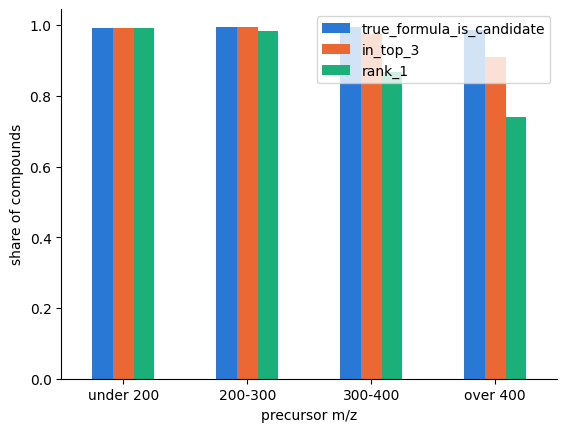

In [29]:
formula_check.drop("all")[["true_formula_is_candidate", "in_top_3", "rank_1"]].plot.bar(rot=0)
plt.xlabel("precursor m/z")
plt.ylabel("share of compounds")
plt.savefig("../reports/figures/02_formula_check.png", dpi=150, bbox_inches="tight")
plt.show()

### Check: averaged counts against the true counts
Mean absolute error, next to the error of always guessing the mean count.

In [30]:
averaged = B.rename(columns=lambda name: name.removeprefix("B_"))[ELEMENTS][usable]
actual = true[ELEMENTS][usable]
feature_error = pd.DataFrame({
    "mean_abs_error": (averaged - actual).abs().mean(),
    "error_if_always_the_mean": (actual - actual.mean()).abs().mean(),
})
feature_error.round(2).to_csv("../reports/tables/formula_feature_error.csv")
feature_error.round(2)

,mean_abs_error,error_if_always_the_mean
C,1.12,4.36
N,0.40,0.87
O,0.39,1.00
S,0.09,0.12
F,0.25,0.32
Cl,0.11,0.25
Br,0.04,0.07


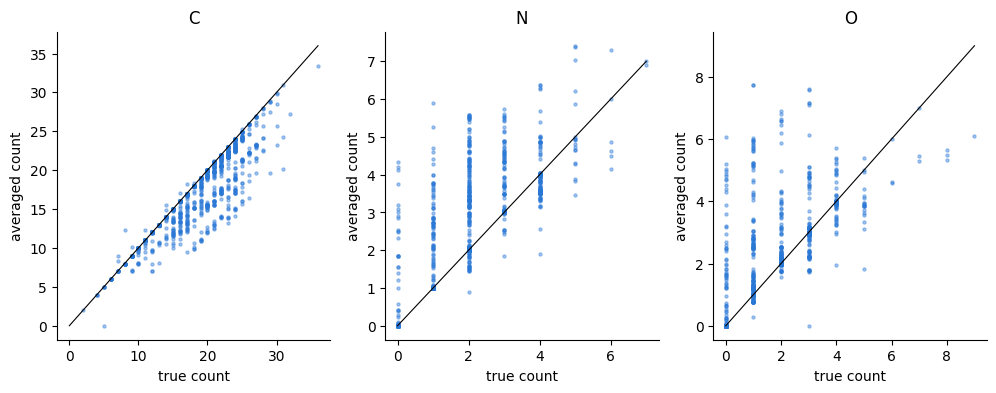

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, element in zip(axes, ["C", "N", "O"]):
    pd.DataFrame({"true count": actual[element], "averaged count": averaged[element]}).plot.scatter(
        "true count", "averaged count", s=5, alpha=0.4, ax=ax, title=element)
    ax.plot([0, actual[element].max()], [0, actual[element].max()], color="black", linewidth=0.8)
plt.savefig("../reports/figures/02_formula_counts.png", dpi=150, bbox_inches="tight")
plt.show()

## Group C: neutral losses

- Loss = precursor m/z minus fragment m/z. A substituent on the part that stays in the fragment shifts the fragment but not the loss, so analogs line up better on losses.
- The losses are binned like the fragments: 650 bins per level, strongest peak kept. Bin 0 holds the peaks within 1 unit of the precursor.

In [32]:
losses = peaks.assign(loss=peaks.precursor_mz - peaks.mz).query("loss >= 0")
C = bin_spectra(losses, "loss", "C_{level}_loss_{bin}")
C.shape

(1570, 1950)

### Example: two similar compounds
Structures compared with Morgan fingerprints (Tanimoto similarity).

In [33]:
generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fingerprints = [generator.GetFingerprint(Chem.MolFromSmiles(s)) for s in compounds.smiles]
similarity = pd.DataFrame([DataStructs.BulkTanimotoSimilarity(fp, fingerprints) for fp in fingerprints], index=X.index, columns=X.index)

### Cosine similarity of the HIGH spectra
Of the fragments, and of the losses.

In [34]:
def cosine_matrix(table):
    unit = table.div(np.linalg.norm(table, axis=1), axis=0).fillna(0)
    return unit @ unit.T


fragments_high = X.filter(like="HIGH_")
losses_high = C.filter(like="C_HIGH_")
fragment_cos = cosine_matrix(fragments_high)
loss_cos = cosine_matrix(losses_high)

### Pair with the largest gain
Similar structures (Tanimoto at least 0.6), precursors at least 14 apart, similar losses (cosine at least 0.8): the pair whose losses match best compared with its fragments.

In [35]:
gap = np.abs(precursor.values[:, None] - precursor.values[None, :])
gain = (loss_cos - fragment_cos).where((similarity >= 0.6) & (loss_cos >= 0.8) & (gap >= 14))
first, second = gain.stack().idxmax()
print(compounds.name[first], "|", compounds.name[second])
print(f"Tanimoto {similarity.loc[first, second]:.2f}, fragment cosine {fragment_cos.loc[first, second]:.2f}, loss cosine {loss_cos.loc[first, second]:.2f}")

3,4-Ethylenedioxy U-47700 | 3,4-Methylenedioxy U-47700
Tanimoto 0.85, fragment cosine 0.01, loss cosine 0.97


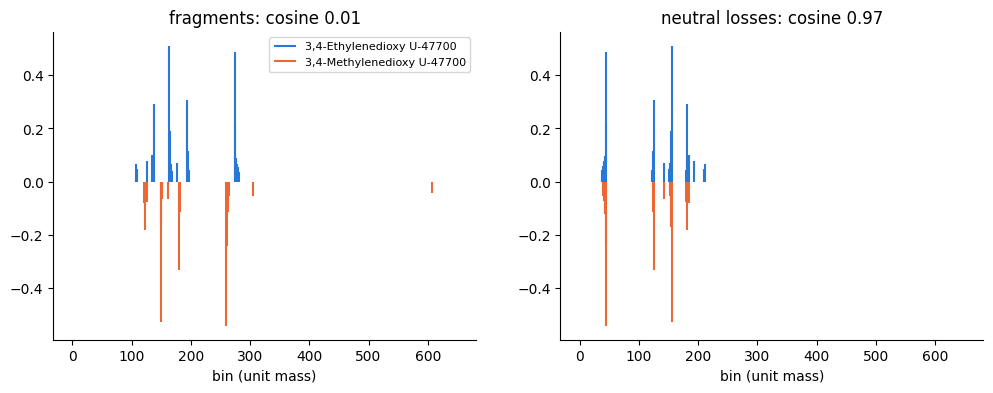

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, title, table, cos in zip(axes, ["fragments", "neutral losses"], [fragments_high, losses_high], [fragment_cos, loss_cos]):
    ax.vlines(range(650), 0, table.loc[first], color="C0", label=compounds.name[first])
    ax.vlines(range(650), 0, -table.loc[second], color="C1", label=compounds.name[second])
    ax.set_title(f"{title}: cosine {cos.loc[first, second]:.2f}")
    ax.set_xlabel("bin (unit mass)")
axes[0].legend(fontsize=8)
plt.savefig("../reports/figures/02_neutral_losses.png", dpi=150, bbox_inches="tight")
plt.show()

## Group D: spectrum summaries

Four numbers per level:
- `n_peaks`: number of cleaned peaks
- `base_mz`: m/z of the strongest peak
- `upper_share`: share of the intensity above half the precursor m/z
- `precursor`: intensity of the intact ion (peak within 0.02 of the precursor m/z, else 0)

### Summaries of each spectrum

In [37]:
by_spectrum = peaks.assign(
    upper=peaks.intensity.where(peaks.mz > peaks.precursor_mz / 2, 0),
    intact=peaks.intensity.where((peaks.mz - peaks.precursor_mz).abs() <= 0.02, 0),
).groupby(spectrum)

summary = pd.DataFrame({
    "n_peaks": by_spectrum.size(),
    "base_mz": peaks.loc[by_spectrum.intensity.idxmax()].set_index(spectrum).mz,
    "upper_share": by_spectrum.upper.sum() / by_spectrum.intensity.sum(),
    "precursor": by_spectrum.intact.max(),
})

### One row per compound

In [38]:
D = summary.unstack("energy")
D.columns = [f"D_{level}_{feature}" for feature, level in D.columns]
D = D[[f"D_{level}_{feature}" for level in LEVELS for feature in summary.columns]].loc[X.index]
D.describe().T[["mean", "min", "max"]]

,mean,min,max
D_LOW_n_peaks,28.578344,2.000000,200.000000
D_LOW_base_mz,289.892741,86.094500,537.158300
D_LOW_upper_share,0.904288,0.249138,1.000000
D_LOW_precursor,0.663688,0.000000,0.944052
D_MID_n_peaks,43.754140,4.000000,200.000000
D_MID_base_mz,234.352843,58.060200,537.158000
D_MID_upper_share,0.791922,0.000000,1.000000
D_MID_precursor,0.391116,0.000000,0.947782
D_HIGH_n_peaks,57.629936,1.000000,200.000000
D_HIGH_base_mz,169.248348,58.003400,537.161700


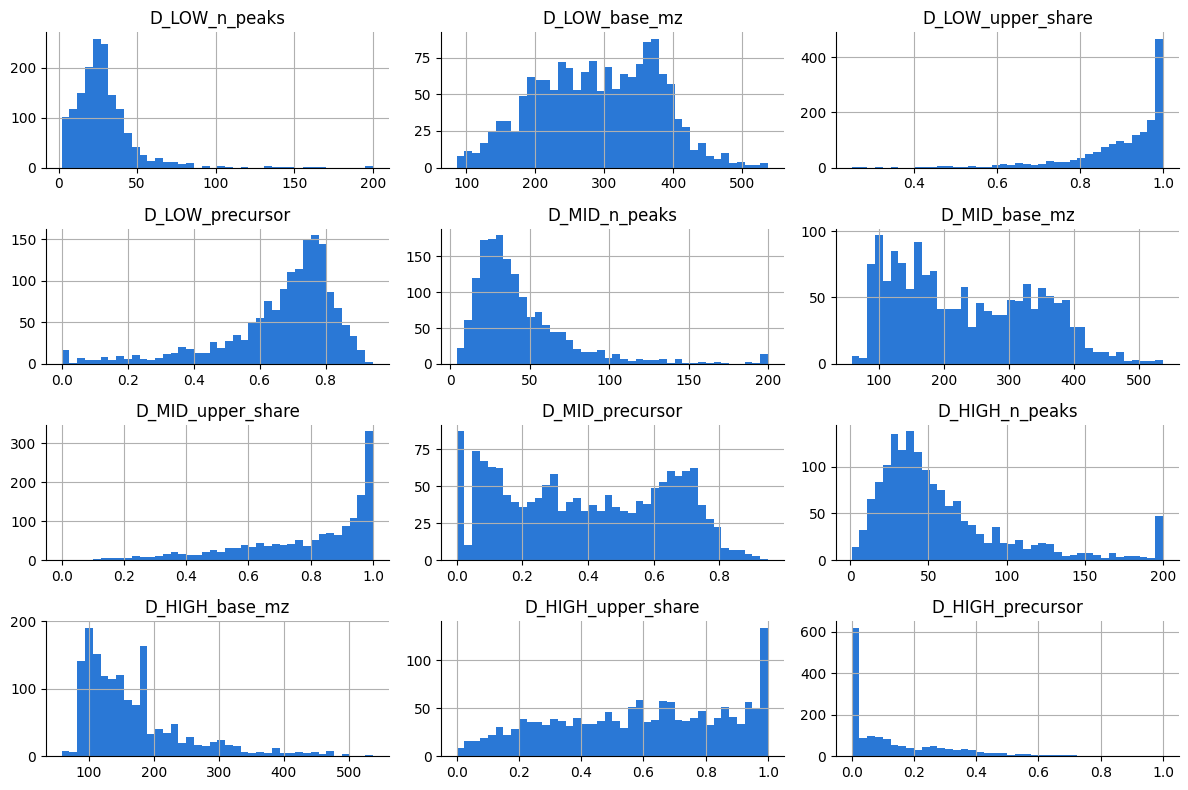

In [39]:
D.hist(bins=40, figsize=(12, 8))
plt.tight_layout()
plt.savefig("../reports/figures/02_summary_features.png", dpi=150, bbox_inches="tight")
plt.show()

## Scale and save
Each new feature is divided by a fixed constant, so that all columns lie roughly between -1 and 1 like the bins of notebook 01. Group C is not scaled.

In [40]:
divisors = {"A_odd_mass": 1, "A_mass_defect": 0.5, "A_kendrick_defect": 0.5, "B_dbe": 25, "B_h_per_c": 3, "B_log_candidates": 4}
divisors |= {f"A_peak_defect_{level}": 0.5 for level in LEVELS}
divisors |= {f"B_{element}": high for element, (low, high) in RANGES.items()}
divisors |= {f"D_{level}_n_peaks": 200 for level in LEVELS} | {f"D_{level}_base_mz": 650 for level in LEVELS}
divisors = pd.Series(divisors)

### Extended matrix
The 1,951 columns of notebook 01 come first, unchanged.

In [41]:
extra = pd.concat([A, B, C, D], axis=1)
X_new = pd.concat([X, extra / divisors.reindex(extra.columns, fill_value=1)], axis=1).rename_axis("inchikey")
X_new.shape

(1570, 3929)

In [42]:
assert X_new.shape == (1570, 3929)
assert X_new.notna().all().all()
assert X_new.index.name == "inchikey"
assert (X_new.iloc[:, :1951] == X).all().all()

### Scaling table

In [43]:
scaling = divisors.reindex(extra.columns[~extra.columns.str.startswith("C_")], fill_value=1)
scaling.rename_axis("feature").rename("divisor").to_csv("../reports/tables/extra_feature_scaling.csv")
scaling.head()

A_odd_mass           1.0
A_mass_defect        0.5
A_kendrick_defect    0.5
A_peak_defect_LOW    0.5
A_peak_defect_MID    0.5
dtype: float64

### Value range of each group

In [44]:
for group in "ABCD":
    part = X_new.filter(regex=f"^{group}_")
    print(group, part.shape[1], part.min().min().round(2), part.max().max().round(2))

A 6 -0.99 1.0
B 10 0.0 1.0
C 1950 0.0 1.0
D 12 0.0 1.0


### Save
Overwrites `X.csv` with the new columns after the 1,951 of notebook 01.

In [45]:
X_new.to_csv("../data/processed/X.csv")